# Exploratory Data Analysis — AdventureWorks sales

This notebook explores the dimensional model built with dbt (`fact_sales`, its dimensions and the sales-reason bridge) to understand the business before building the dashboard. Each section poses a question, shows the code and chart, and ends with the insight and what it means for the dashboard.

**Business questions covered** (from the challenge): **a** orders, quantity and value across dimensions · **b** products by average order value · **c** top customers · **d** top cities · **e** time series · **f** best-selling product under the "Promotion" sales reason.

**Definitions used throughout** (see `docs/regras_de_negocio.md`):
- *Gross sales* = `orderqty × unitprice`; *net sales* = gross − discount. "Value" means **net sales** unless stated.
- *Orders* are always counted with `count(distinct fk_salesorderid)`; the fact grain is the order line.
- City, state and country come from the **ship-to** address.

**Contents:** 1 Data profile and reconciliation · 2 Headline numbers · 3 Time series (e) · 4 Sales channels · 5 Products (a, b) · 6 Customers (c) · 7 Geography (d) · 8 Payment · 9 Sales reasons (f) · 10 Discounts · 11 Data caveats and recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import warnings
warnings.filterwarnings("ignore")

catalog = "dev"
mart_schema = "dbt_lmilaremietto"  # schema where dbt materializes the marts
mart = f"{catalog}.{mart_schema}"
raw = f"{catalog}.postgres_adventureworks"

pd.set_option("display.max_columns", None)
pd.options.display.float_format = "{:,.2f}".format

# One color per entity, reused in every chart
BLUE, ORANGE, GRAY, LIGHT_BLUE = "#2a78d6", "#eb6834", "#898781", "#9ec5f4"
CHANNEL_COLORS = {"Online": BLUE, "Reseller": ORANGE}
INK, GRID, SURFACE = "#0b0b0b", "#e1e0d9", "#fcfcfb"

plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "font.size": 11,
})


def query(sql):
    """Run a SQL query and return a pandas DataFrame with Decimal columns converted to numbers."""
    frame = spark.sql(sql).toPandas()
    for column in frame.columns:
        try:
            frame[column] = pd.to_numeric(frame[column])
        except (ValueError, TypeError):
            pass
    return frame


def millions(value, _=None):
    return f"${value / 1e6:,.1f}M"


def thousands(value, _=None):
    return f"${value / 1e3:,.0f}K"


def horizontal_grid(ax):
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)


def label_bars(ax, fmt, horizontal=True):
    """Write the value at the end of each bar."""
    for bar in ax.patches:
        if horizontal:
            ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  {fmt(bar.get_width())}",
                    va="center", ha="left", fontsize=10, color=INK)
        else:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), fmt(bar.get_height()),
                    va="bottom", ha="center", fontsize=10, color=INK)

## 1. Data profile and reconciliation

**Question:** is the model complete and does it agree with the source? Before any analysis, check table sizes, compare the mart with the raw tables, and measure missing values that will shape the dashboard.

In [2]:
tables = ["fact_sales", "dim_products", "dim_customers", "dim_addresses",
          "dim_credit_cards", "dim_dates", "dim_sales_reasons", "bridge_sales_order_reasons"]
row_counts = pd.DataFrame({
    "table": tables,
    "rows": [int(query(f"select count(*) as n from {mart}.{table}")["n"][0]) for table in tables],
})
display(row_counts)

,table,rows
0,fact_sales,121317
1,dim_products,504
2,dim_customers,19820
3,dim_addresses,19614
4,dim_credit_cards,19118
5,dim_dates,1461
6,dim_sales_reasons,10
7,bridge_sales_order_reasons,27647


In [3]:
# Mart vs raw: same orders, same lines, same gross sales
reconciliation = query(f"""
    select
        'raw' as source
        , (select count(*) from {raw}.salesorderheader) as orders
        , count(*) as order_lines
        , sum(orderqty * unitprice) as gross_sales
        , cast(null as double) as gross_sales_2011
    from {raw}.salesorderdetail
    union all
    select
        'mart'
        , count(distinct fk_salesorderid)
        , count(*)
        , sum(salesorderdetailsubtotal)
        , sum(case when year(orderdate) = 2011 then salesorderdetailsubtotal end)
    from {mart}.fact_sales
""")
display(reconciliation)

gross_2011 = reconciliation.loc[reconciliation["source"] == "mart", "gross_sales_2011"].iloc[0]
print(f"2011 gross sales in the mart: {gross_2011:,.2f}  (CEO reference: 12,646,112.16)")

2011 gross sales in the mart: 12,646,112.16  (CEO reference: 12,646,112.16)


,source,orders,order_lines,gross_sales,gross_sales_2011
0,raw,31465,121317,"110,373,889.31",NaN
1,mart,31465,121317,"110,373,889.31","12,646,112.16"


In [4]:
# Coverage of optional attributes by channel
coverage = query(f"""
    select
        case when f.onlineorderflag then 'Online' else 'Reseller' end as channel
        , count(distinct f.fk_salesorderid) as orders
        , count(distinct case when f.fk_creditcardid is null then f.fk_salesorderid end) as orders_without_card
        , count(distinct case when b.fk_salesorderid is null then f.fk_salesorderid end) as orders_without_reason
    from {mart}.fact_sales as f
    left join (select distinct fk_salesorderid from {mart}.bridge_sales_order_reasons) as b
        on f.fk_salesorderid = b.fk_salesorderid
    group by 1
    order by 1
""")
coverage.loc[len(coverage)] = ["Total"] + coverage.drop(columns="channel").sum().tolist()
display(coverage)

,channel,orders,orders_without_card,orders_without_reason
0,Online,27659,1124,4647
1,Reseller,3806,7,3806
2,Total,31465,1131,8453


**Insight**
- The mart has the same orders, order lines and gross sales as the raw tables, and the 2011 gross sales match the CEO's reference value to the cent. The transformation did not lose or duplicate anything.
- Two attributes are not always present. **1,131 orders have no credit card** and **8,453 orders have no sales reason**. The dashboard must keep them visible ("No card", "No reason") instead of dropping them, otherwise totals by card type or by reason will not add up to the overall total.
- The missing sales reasons are not random: see section 9.

## 2. Headline numbers

**Question:** how big is the business, and what does a typical order look like?

In [5]:
kpis = query(f"""
    select
        count(distinct fk_salesorderid) as orders
        , count(distinct fk_customerid) as customers
        , count(distinct fk_productid) as products_sold
        , sum(orderqty) as units
        , sum(salesorderdetailsubtotal) as gross_sales
        , sum(salesorderdetaildiscount) as discounts
        , sum(salesorderdetailnetsubtotal) as net_sales
        , min(orderdate) as first_order
        , max(orderdate) as last_order
    from {mart}.fact_sales
""").iloc[0]
catalog_size = int(query(f"select count(*) as n from {mart}.dim_products")["n"][0])

summary = pd.DataFrame({"value": {
    "Orders": f"{kpis['orders']:,.0f}",
    "Customers": f"{kpis['customers']:,.0f}",
    "Products sold (of catalog)": f"{kpis['products_sold']:,.0f} of {catalog_size:,}",
    "Units": f"{kpis['units']:,.0f}",
    "Gross sales": f"${kpis['gross_sales']:,.0f}",
    "Discounts": f"${kpis['discounts']:,.0f} ({kpis['discounts'] / kpis['gross_sales']:.2%} of gross)",
    "Net sales": f"${kpis['net_sales']:,.0f}",
    "Average order value (net)": f"${kpis['net_sales'] / kpis['orders']:,.0f}",
    "Units per order": f"{kpis['units'] / kpis['orders']:.1f}",
    "Order period": f"{kpis['first_order']} to {kpis['last_order']}",
}})
display(summary)

,value
Orders,"31,465"
Customers,"19,119"
Products sold (of catalog),266 of 504
Units,"274,914"
Gross sales,"$110,373,889"
Discounts,"$527,508 (0.48% of gross)"
Net sales,"$109,846,381"
Average order value (net),"$3,491"
Units per order,8.7
Order period,2011-05-31 to 2014-06-30


**Insight**
- 31,465 orders and 19,119 customers generated **US$ 109.8M in net sales** over three years, at about US$ 3,490 per order.
- Discounts are almost irrelevant at the aggregate level (0.48% of gross sales). Section 10 shows where they do exist.
- Only 266 of the 504 catalog products were ever sold. The dashboard's product filter should not rely on `dim_products` alone, or it will list 238 products with no sales.

## 3. Time series (question e)

**Question:** how do orders, units and value evolve by year and month?

Net sales growth, 2013 vs 2012 (the only two full years): 30.1%


,calendar_year,first_day,last_day,orders,units,net_sales
0,2011,2011-05-31,2011-12-31,1607,12888,"12,641,672.21"
1,2012,2012-01-01,2012-12-31,3915,68579,"33,524,301.32"
2,2013,2013-01-01,2013-12-31,14182,131788,"43,622,479.05"
3,2014,2014-01-01,2014-06-30,11761,61659,"20,057,928.81"


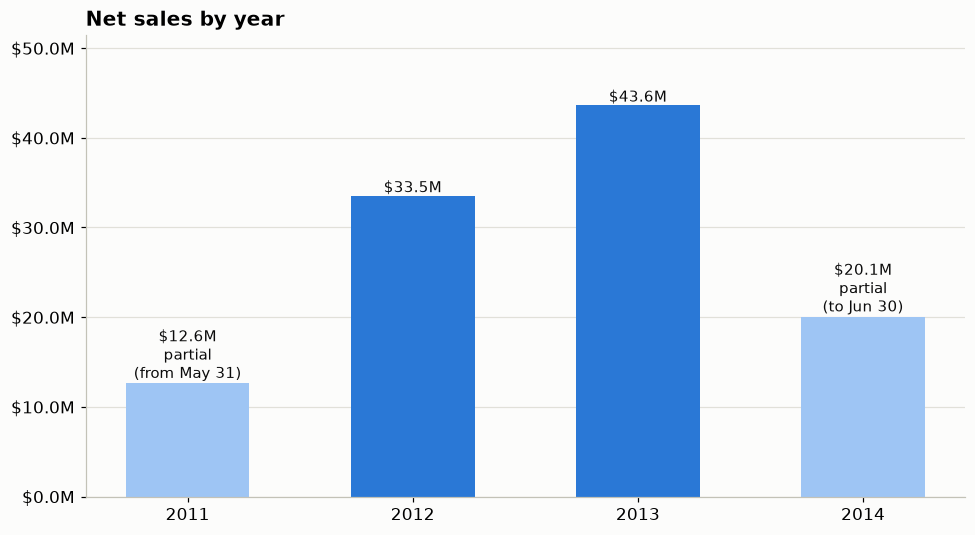

In [6]:
yearly = query(f"""
    select
        d.calendar_year
        , min(f.orderdate) as first_day
        , max(f.orderdate) as last_day
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.orderqty) as units
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    join {mart}.dim_dates as d on f.orderdate = d.pk_date
    group by 1
    order by 1
""")
display(yearly)

full_years = yearly[yearly["calendar_year"].isin([2012, 2013])].set_index("calendar_year")["net_sales"]
print(f"Net sales growth, 2013 vs 2012 (the only two full years): {full_years[2013] / full_years[2012] - 1:.1%}")

fig, ax = plt.subplots(figsize=(9, 5))
partial = {2011: "partial\n(from May 31)", 2014: "partial\n(to Jun 30)"}
colors = [LIGHT_BLUE if year in partial else BLUE for year in yearly["calendar_year"]]
ax.bar(yearly["calendar_year"].astype(str), yearly["net_sales"], color=colors, width=0.55)
for position, (year, value) in enumerate(zip(yearly["calendar_year"], yearly["net_sales"])):
    note = f"\n{partial[year]}" if year in partial else ""
    ax.text(position, value, f"{millions(value)}{note}", ha="center", va="bottom", fontsize=10, color=INK)
ax.set_title("Net sales by year")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(millions))
ax.margins(y=0.18)
plt.tight_layout()
plt.show()

In [7]:
# Same months in every year (January-May) to compare growth fairly
same_months = query(f"""
    select
        d.calendar_year
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    join {mart}.dim_dates as d on f.orderdate = d.pk_date
    where d.calendar_month between 1 and 5 and d.calendar_year >= 2012
    group by 1
    order by 1
""")
same_months["net_sales_growth_pct"] = same_months["net_sales"].pct_change() * 100
display(same_months)

,calendar_year,orders,net_sales,net_sales_growth_pct
0,2012,1421,"13,131,006.04",NaN
1,2013,2022,"13,594,753.25",3.53
2,2014,10822,"20,008,922.97",47.18


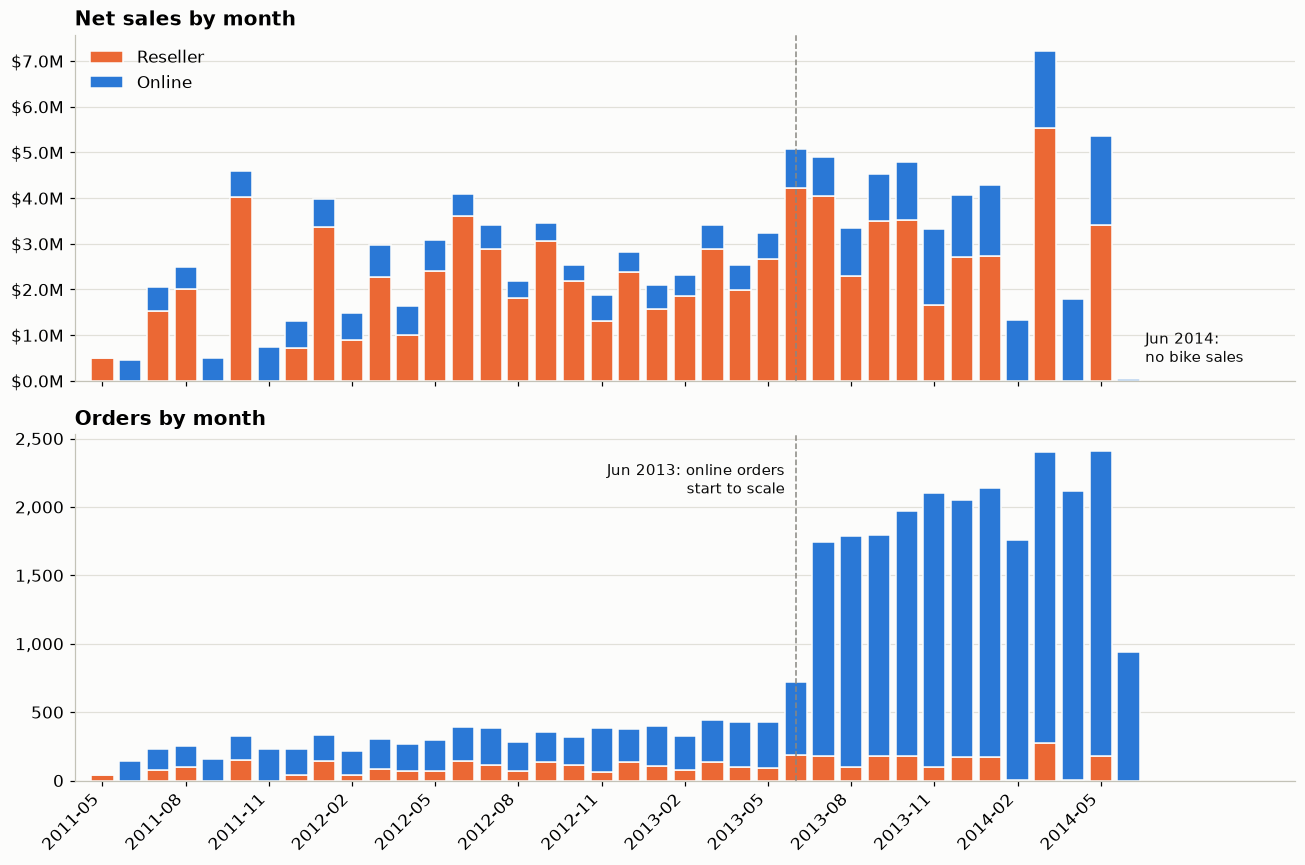

In [8]:
monthly = query(f"""
    select
        d.year_month
        , case when f.onlineorderflag then 'Online' else 'Reseller' end as channel
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.orderqty) as units
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    join {mart}.dim_dates as d on f.orderdate = d.pk_date
    group by 1, 2
    order by 1, 2
""")
months = sorted(monthly["year_month"].unique())


def by_channel(column):
    pivoted = monthly.pivot(index="year_month", columns="channel", values=column)
    return pivoted.reindex(months).fillna(0)[["Reseller", "Online"]]


fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
panels = [(axes[0], "net_sales", "Net sales by month", millions),
          (axes[1], "orders", "Orders by month", lambda value, _=None: f"{value:,.0f}")]
for ax, column, title, formatter in panels:
    data = by_channel(column)
    bottom = np.zeros(len(data))
    for channel in data.columns:
        ax.bar(data.index, data[channel], bottom=bottom, color=CHANNEL_COLORS[channel],
               label=channel, width=0.8, edgecolor=SURFACE, linewidth=1)
        bottom += data[channel].to_numpy()
    ax.set_title(title)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(formatter))
axes[0].legend(frameon=False, loc="upper left")
axes[1].set_xticks(range(0, len(months), 3))
axes[1].set_xticklabels(months[::3], rotation=45, ha="right")
for ax in axes:
    ax.axvline(months.index("2013-06"), color=GRAY, linestyle="--", linewidth=1)
axes[1].text(months.index("2013-06") - 0.4, axes[1].get_ylim()[1] * 0.92, "Jun 2013: online orders\nstart to scale",
             ha="right", va="top", fontsize=10, color=INK)
axes[0].set_xlim(-1, len(months) + 5)
axes[0].text(months.index("2014-06") + 0.6, 3e5, "Jun 2014:\nno bike sales", ha="left", va="bottom", fontsize=10, color=INK)
plt.tight_layout()
plt.show()

**Insight**
- **Growth is real but uneven.** Net sales grew about 30% from 2012 (US$ 33.5M) to 2013 (US$ 43.6M), the only two full years. But January-May 2013 was only about 3.5% above January-May 2012; the 2013 gain came from the second half, and January-May 2014 is about 47% above 2013.
- **2011 and 2014 are partial years.** 2011 starts on May 31 and 2014 ends on June 30. Year-over-year comparisons in the dashboard should compare equal month ranges, or show only 2012 and 2013.
- **The monthly line is lumpy because reseller sales are lumpy.** Some months have almost no reseller orders (June, September and November 2011; February, April and June 2014), which makes net sales swing by millions from one month to the next. Online sales are far steadier.
- **From mid-2013 the number of orders jumps** (from a few hundred to 1,700-2,400 a month) while net sales per month rise by much less. Section 4 explains why.
- **June 2014 is incomplete**: 939 orders and only US$ 49K, with no bike sales at all. Treat it as a data cut-off, not as a collapse in demand, and consider excluding it from trend lines and from growth KPIs.

## 4. Sales channels

**Question:** the `onlineorderflag` splits orders into online and reseller (store) orders. How different are the two?

,channel,orders,net_sales,avg_order_value,median_order_value,units_per_order,share_of_orders_pct,share_of_net_sales_pct
0,Online,27659,"29,358,677.22","1,061.45",594.97,2.18,87.90,26.73
1,Reseller,3806,"80,487,704.18","21,147.58","8,257.08",56.36,12.10,73.27


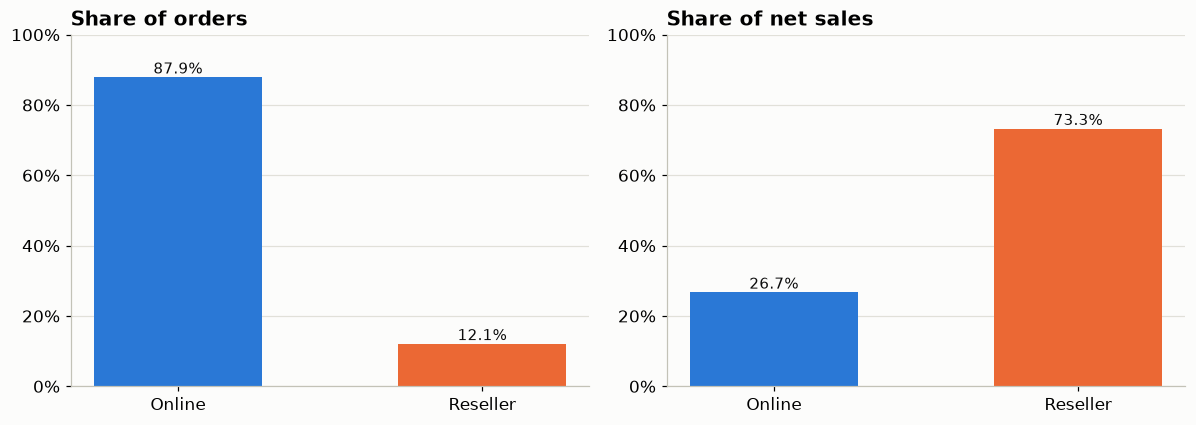

In [9]:
channels = query(f"""
    with orders as (
        select
            fk_salesorderid
            , max(case when onlineorderflag then 'Online' else 'Reseller' end) as channel
            , sum(salesorderdetailnetsubtotal) as net_sales
            , sum(orderqty) as units
        from {mart}.fact_sales
        group by 1
    )
    select
        channel
        , count(*) as orders
        , sum(net_sales) as net_sales
        , avg(net_sales) as avg_order_value
        , percentile(net_sales, 0.5) as median_order_value
        , sum(units) / count(*) as units_per_order
    from orders
    group by 1
    order by 1
""")
channels["share_of_orders_pct"] = channels["orders"] / channels["orders"].sum() * 100
channels["share_of_net_sales_pct"] = channels["net_sales"] / channels["net_sales"].sum() * 100
display(channels)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column, title in [(axes[0], "share_of_orders_pct", "Share of orders"),
                          (axes[1], "share_of_net_sales_pct", "Share of net sales")]:
    ax.bar(channels["channel"], channels[column], color=[CHANNEL_COLORS[c] for c in channels["channel"]], width=0.55)
    ax.set_title(title)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    label_bars(ax, lambda value: f"{value:.1f}%", horizontal=False)
plt.tight_layout()
plt.show()

In [10]:
# What changed in online sales when orders jumped in mid-2013?
online_shift = query(f"""
    select
        case when f.orderdate < date'2013-07-01' then '2011-05 to 2013-06' else '2013-07 to 2014-05' end as period
        , count(distinct date_format(f.orderdate, 'yyyy-MM')) as months
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.salesorderdetailnetsubtotal) as net_sales
        , count(distinct case when p.productcategory_name = 'Bikes' then f.fk_salesorderid end) as orders_with_bikes
        , count(distinct case when p.productcategory_name = 'Accessories' then f.fk_salesorderid end) as orders_with_accessories
        , count(distinct case when p.productcategory_name = 'Clothing' then f.fk_salesorderid end) as orders_with_clothing
    from {mart}.fact_sales as f
    join {mart}.dim_products as p on f.fk_productid = p.pk_productid
    where f.onlineorderflag and f.orderdate < date'2014-06-01'
    group by 1
    order by 1
""")
online_shift["orders_per_month"] = online_shift["orders"] / online_shift["months"]
online_shift["net_sales_per_month"] = online_shift["net_sales"] / online_shift["months"]
online_shift["avg_order_value"] = online_shift["net_sales"] / online_shift["orders"]
display(online_shift)

,period,months,orders,net_sales,orders_with_bikes,orders_with_accessories,orders_with_clothing,orders_per_month,net_sales_per_month,avg_order_value
0,2011-05 to 2013-06,26,5988,"13,743,332.16",5953,430,166,230.31,"528,589.70","2,295.15"
1,2013-07 to 2014-05,11,20732,"15,566,339.22",9252,16944,6957,"1,884.73","1,415,121.75",750.84


**Insight**
- **Two very different businesses share one fact table.** Resellers are 12% of orders but about 73% of net sales (average order about US$ 21,100); online orders are 88% of orders but about 27% of net sales (average order about US$ 1,060). Every average that mixes the two (average order value, units per order) hides this, so **channel must be a dashboard filter**.
- In this dataset **the channel is the customer type**: every reseller order belongs to a `Store` customer and every online order to an `Individual` customer.
- **Online growth in mid-2013 is a change of product mix, not only of volume.** Online orders went from about 230 to about 1,880 a month and online net sales per month rose about 2.7x, but the average online order fell from about US$ 2,300 to about US$ 750. The reason is that accessories and clothing, almost absent from online orders before, appear in tens of thousands of orders (accessory orders: 430 before, 16,944 after). Bike orders also grew (5,953 to 9,252).

## 5. Products (questions a and b)

**Question:** which categories and products drive value, and which products have the highest average order value (net sales / orders, as defined in question b)?

,category,orders,units,net_sales,share_of_net_sales_pct
0,Bikes,18368,90268,"94,651,172.70",86.17
1,Components,2650,49044,"11,802,593.29",10.74
2,Clothing,9877,73670,"2,120,542.52",1.93
3,Accessories,19524,61932,"1,272,072.88",1.16


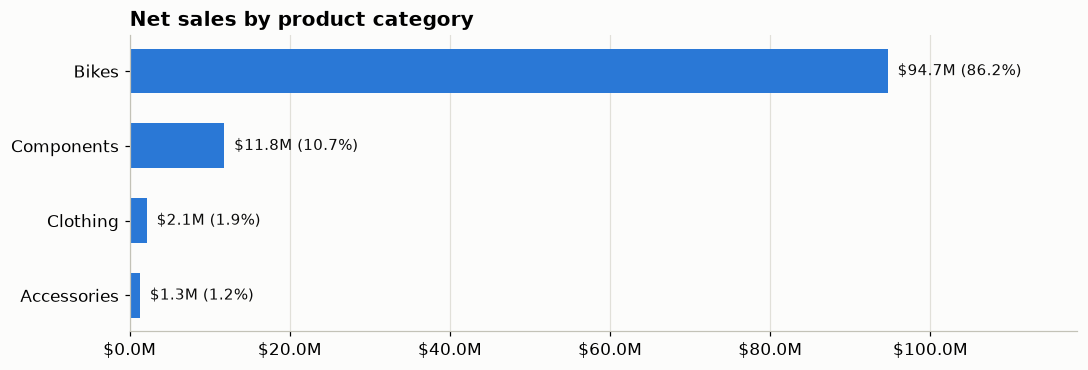

In [11]:
categories = query(f"""
    select
        p.productcategory_name as category
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.orderqty) as units
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    join {mart}.dim_products as p on f.fk_productid = p.pk_productid
    group by 1
    order by net_sales desc
""")
categories["share_of_net_sales_pct"] = categories["net_sales"] / categories["net_sales"].sum() * 100
display(categories)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(categories["category"], categories["net_sales"], color=BLUE, height=0.6)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(millions))
ax.set_title("Net sales by product category")
horizontal_grid(ax)
label_bars(ax, lambda value: f"{millions(value)} ({value / categories['net_sales'].sum():.1%})")
ax.margins(x=0.25)
plt.tight_layout()
plt.show()

Top 10 products = 28.2% of net sales


,product_name,units,net_sales
0,"Mountain-200 Black, 38",2977,"4,400,592.80"
1,"Mountain-200 Black, 42",2664,"4,009,494.76"
2,"Mountain-200 Silver, 38",2394,"3,693,678.03"
3,"Mountain-200 Silver, 42",2234,"3,438,478.86"
4,"Mountain-200 Silver, 46",2216,"3,434,256.94"
5,"Mountain-200 Black, 46",2111,"3,309,673.22"
6,"Road-250 Black, 44",1642,"2,516,857.31"
7,"Road-250 Black, 48",1498,"2,347,655.95"
8,"Road-250 Black, 52",1245,"2,012,447.77"
9,"Road-150 Red, 56",664,"1,847,818.63"


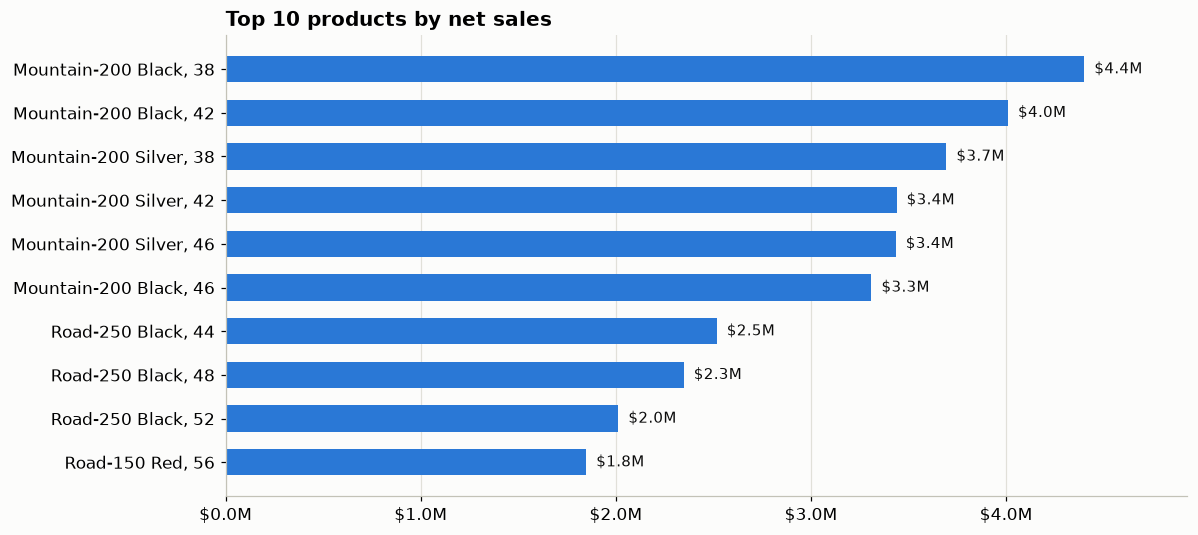

In [12]:
top_products = query(f"""
    select
        p.product_name
        , sum(f.orderqty) as units
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    join {mart}.dim_products as p on f.fk_productid = p.pk_productid
    group by 1
    order by net_sales desc
    limit 10
""")
total_net = float(kpis["net_sales"])
display(top_products)
print(f"Top 10 products = {top_products['net_sales'].sum() / total_net:.1%} of net sales")

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top_products["product_name"], top_products["net_sales"], color=BLUE, height=0.6)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(millions))
ax.set_title("Top 10 products by net sales")
horizontal_grid(ax)
label_bars(ax, millions)
ax.margins(x=0.12)
plt.tight_layout()
plt.show()

,product_name,orders,net_sales,avg_order_value
0,"Mountain-100 Black, 38",234,"1,339,997.25","5,726.48"
1,"Mountain-100 Black, 44",242,"1,365,852.38","5,644.02"
2,"Mountain-100 Black, 42",228,"1,254,722.73","5,503.17"
3,"Mountain-100 Silver, 42",221,"1,186,494.85","5,368.75"
4,"Mountain-100 Silver, 38",241,"1,291,868.70","5,360.45"
5,"Mountain-100 Silver, 44",233,"1,217,210.36","5,224.08"
6,"Mountain-100 Black, 48",243,"1,234,276.03","5,079.33"
7,"Mountain-100 Silver, 48",204,"1,019,657.00","4,998.32"
8,"Road-250 Red, 44",364,"1,448,122.48","3,978.36"
9,"Touring-1000 Blue, 60",439,"1,721,242.51","3,920.83"


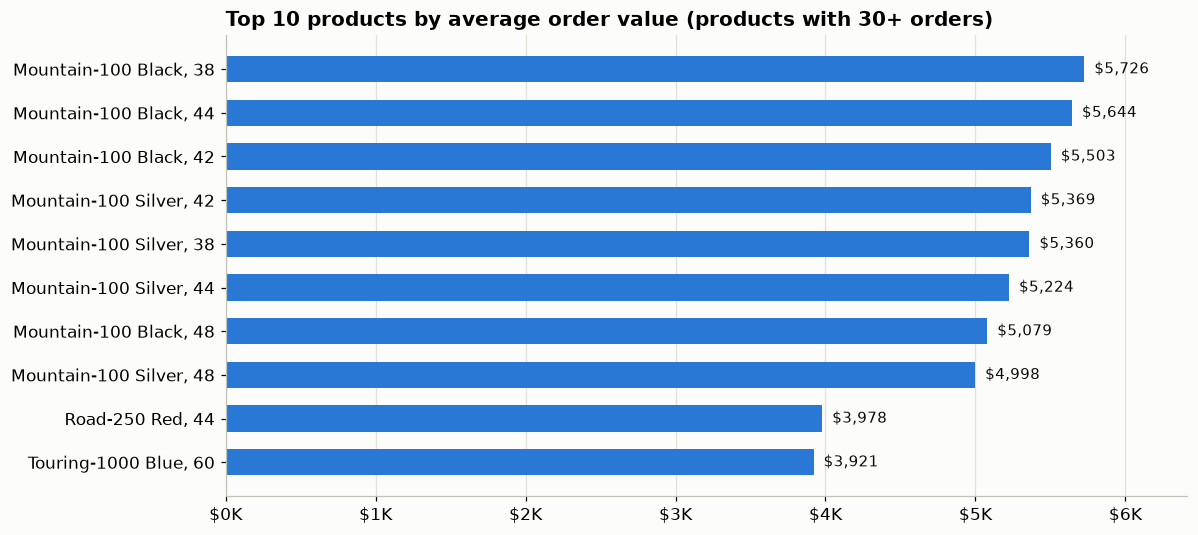

In [13]:
# Question b: average order value per product = (gross sales - discounts) / orders
# Products with fewer than 30 orders are excluded so that rare items do not dominate the ranking
product_aov = query(f"""
    select
        p.product_name
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.salesorderdetailnetsubtotal) as net_sales
        , sum(f.salesorderdetailnetsubtotal) / count(distinct f.fk_salesorderid) as avg_order_value
    from {mart}.fact_sales as f
    join {mart}.dim_products as p on f.fk_productid = p.pk_productid
    group by 1
    having count(distinct f.fk_salesorderid) >= 30
    order by avg_order_value desc
    limit 10
""")
display(product_aov)

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(product_aov["product_name"], product_aov["avg_order_value"], color=BLUE, height=0.6)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(thousands))
ax.set_title("Top 10 products by average order value (products with 30+ orders)")
horizontal_grid(ax)
label_bars(ax, lambda value: f"${value:,.0f}")
ax.margins(x=0.12)
plt.tight_layout()
plt.show()

**Insight**
- **Bikes are the business**: about 86% of net sales, followed by Components (about 11%). Clothing and Accessories together are about 3% of value, although Accessories alone appear in 62% of orders.
- **Product concentration is moderate.** The top 10 products are 28% of net sales out of 266 products sold; six of them are Mountain-200 variants, three are Road-250 and one is Road-150. The concentration is at the category level (bikes), not in individual products.
- **For question b, the top of the ranking is the Mountain-100 family** (about US$ 5,000-5,700 per order), followed by Road-250 and Touring-1000. The ranking is dominated by high-price bikes, which is expected: average order value mostly reflects unit price and typical quantity. Use the minimum-orders threshold (30 here) as a dashboard parameter, otherwise a product sold once in a large order tops the list.

## 6. Customers (question c)

**Question:** who are the top customers and how concentrated is revenue?

Top 10 customers = 7.2% of net sales


,pk_customerid,customer_name,customer_type,orders,net_sales
0,29818,Brakes and Gears,Store,12,"877,107.19"
1,29715,Excellent Riding Supplies,Store,12,"853,849.18"
2,29722,Vigorous Exercise Company,Store,12,"841,908.77"
3,30117,Totes & Baskets Company,Store,12,"816,755.58"
4,29614,Retail Mall,Store,12,"799,277.90"
5,29639,Corner Bicycle Supply,Store,12,"787,773.04"
6,29701,Outdoor Equipment Store,Store,8,"746,317.53"
7,29617,Thorough Parts and Repair Services,Store,12,"740,985.83"
8,29994,"Health Spa, Limited",Store,12,"730,798.71"
9,29646,Fitness Toy Store,Store,12,"727,272.65"


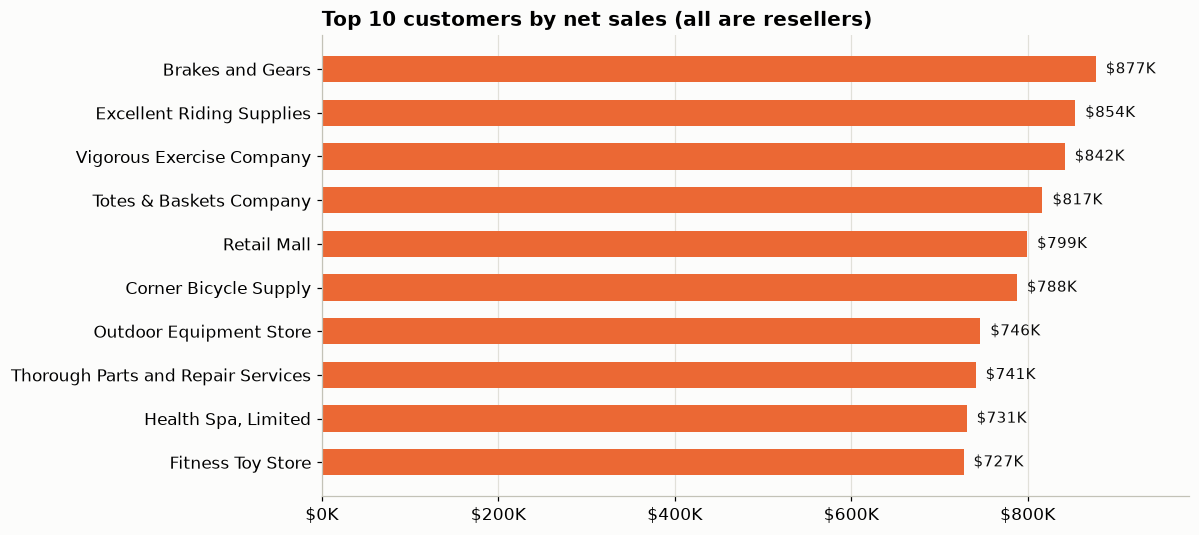

In [14]:
top_customers = query(f"""
    select
        c.pk_customerid
        , c.customer_name
        , c.customer_type
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    join {mart}.dim_customers as c on f.fk_customerid = c.pk_customerid
    group by 1, 2, 3
    order by net_sales desc
    limit 10
""")
display(top_customers)
print(f"Top 10 customers = {top_customers['net_sales'].sum() / total_net:.1%} of net sales")

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top_customers["customer_name"], top_customers["net_sales"], color=ORANGE, height=0.6)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(thousands))
ax.set_title("Top 10 customers by net sales (all are resellers)")
horizontal_grid(ax)
label_bars(ax, thousands)
ax.margins(x=0.12)
plt.tight_layout()
plt.show()

Top 10% of customers = 81.6% of net sales; customers with a single order: 60.9%; average orders per customer: 1.65


,customers,orders,net_sales,share_of_customers_pct,share_of_net_sales_pct
customer_type,,,,,
Individual,18484,27659,"29,358,677.22",96.68,26.73
Store,635,3806,"80,487,704.18",3.32,73.27


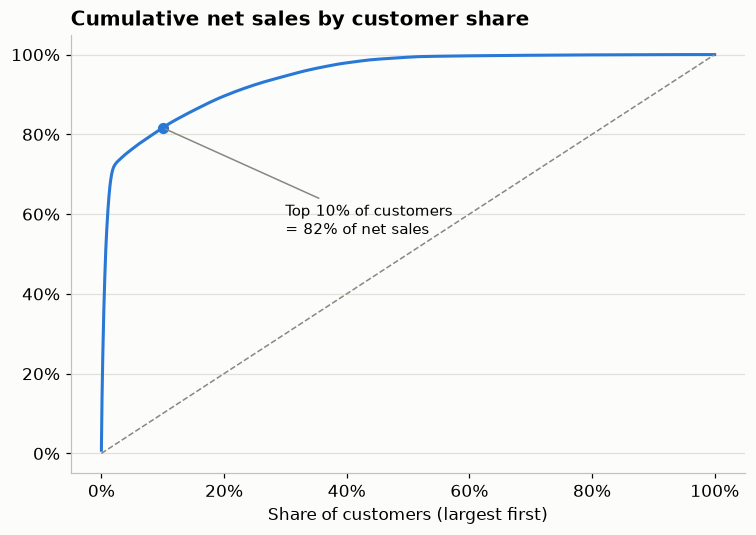

In [15]:
customer_net = query(f"""
    select
        c.customer_type
        , f.fk_customerid
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    join {mart}.dim_customers as c on f.fk_customerid = c.pk_customerid
    group by 1, 2
""")
by_type = customer_net.groupby("customer_type").agg(
    customers=("fk_customerid", "count"), orders=("orders", "sum"), net_sales=("net_sales", "sum"))
by_type["share_of_customers_pct"] = by_type["customers"] / by_type["customers"].sum() * 100
by_type["share_of_net_sales_pct"] = by_type["net_sales"] / by_type["net_sales"].sum() * 100
display(by_type)

customer_net = customer_net.sort_values("net_sales", ascending=False).reset_index(drop=True)
customer_net["cum_share_customers"] = (customer_net.index + 1) / len(customer_net)
customer_net["cum_share_net_sales"] = customer_net["net_sales"].cumsum() / customer_net["net_sales"].sum()
top_decile = customer_net.loc[customer_net["cum_share_customers"] <= 0.10, "cum_share_net_sales"].iloc[-1]
one_order = (customer_net["orders"] == 1).mean()
print(f"Top 10% of customers = {top_decile:.1%} of net sales; customers with a single order: {one_order:.1%}; "
      f"average orders per customer: {customer_net['orders'].mean():.2f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(customer_net["cum_share_customers"] * 100, customer_net["cum_share_net_sales"] * 100, color=BLUE, linewidth=2)
ax.plot([0, 100], [0, 100], color=GRAY, linestyle="--", linewidth=1)
ax.scatter([10], [top_decile * 100], color=BLUE, s=40, zorder=3)
ax.annotate(f"Top 10% of customers\n= {top_decile:.0%} of net sales", xy=(10, top_decile * 100), xytext=(30, 55), fontsize=10,
            arrowprops={"arrowstyle": "-", "color": GRAY})
ax.set_title("Cumulative net sales by customer share")
ax.set_xlabel("Share of customers (largest first)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.tight_layout()
plt.show()

**Insight**
- **The top 10 customers are all resellers (stores)**, each with 8-12 orders and roughly US$ 0.73M-0.88M of net sales; together they are about 7% of total net sales. No single customer is dominant: the largest is below 1% of the total.
- **Revenue is concentrated in a small group.** The 635 reseller customers (3% of customers) generate about 73% of net sales, and the top 10% of customers account for about 82%.
- **Most individual customers buy once.** About 61% of customers placed a single order, and the average is 1.65 orders per customer. Retention of individual customers is the main growth lever on the online side.
- The ranking should group by `pk_customerid`, not by name, so that customers with the same name stay separate.

## 7. Geography (question d)

**Question:** which cities, states and countries concentrate sales? (Ship-to address, see `docs/regras_de_negocio.md`.)

Top 5 cities = 11.0% of net sales


,city,state,country,orders,net_sales,avg_order_value
0,Toronto,Ontario,Canada,176,"4,460,477.68","25,343.62"
1,London,England,United Kingdom,756,"2,738,540.21","3,622.41"
2,Paris,Seine (Paris),France,575,"1,991,775.21","3,463.96"
3,Seattle,Washington,United States,133,"1,569,985.41","11,804.40"
4,Burnaby,British Columbia,Canada,98,"1,333,731.23","13,609.50"


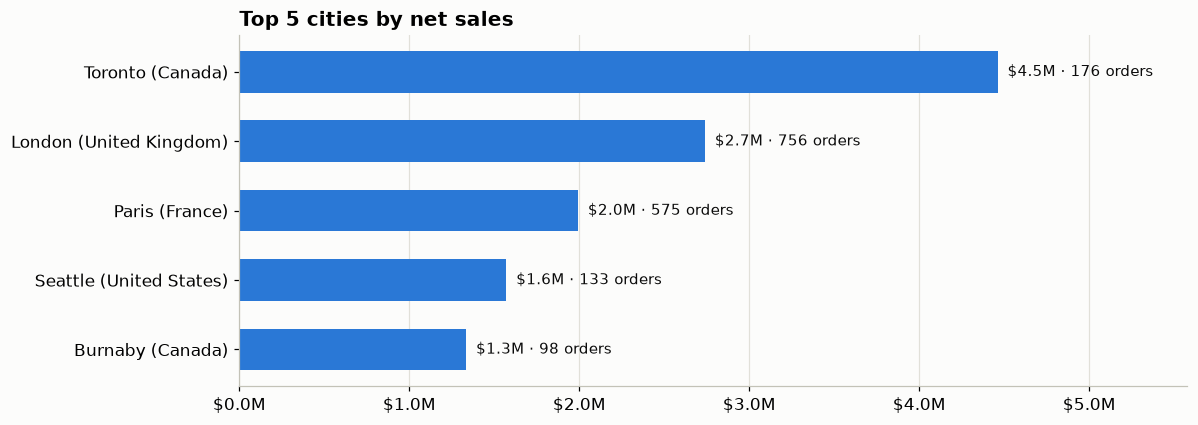

In [16]:
cities = query(f"""
    select
        a.city
        , a.stateprovince_name as state
        , a.countryregion_name as country
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    join {mart}.dim_addresses as a on f.fk_shiptoaddressid = a.pk_addressid
    group by 1, 2, 3
    order by net_sales desc
    limit 5
""")
cities["avg_order_value"] = cities["net_sales"] / cities["orders"]
display(cities)
print(f"Top 5 cities = {cities['net_sales'].sum() / total_net:.1%} of net sales")

labels = cities["city"] + " (" + cities["country"] + ")"
fig, ax = plt.subplots(figsize=(11, 4))
ax.barh(labels, cities["net_sales"], color=BLUE, height=0.6)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(millions))
ax.set_title("Top 5 cities by net sales")
horizontal_grid(ax)
for bar, orders in zip(ax.patches, cities["orders"]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  {millions(bar.get_width())} · {orders:,} orders",
            va="center", ha="left", fontsize=10, color=INK)
ax.margins(x=0.25)
plt.tight_layout()
plt.show()

,country,orders,units,net_sales,share_of_net_sales_pct,avg_order_value
0,United States,12041,154092,"62,997,590.71",57.35,"5,231.92"
1,Canada,4067,49381,"16,355,770.45",14.89,"4,021.58"
2,Australia,6843,18293,"10,655,335.96",9.70,"1,557.11"
3,United Kingdom,3219,20099,"7,670,721.04",6.98,"2,382.95"
4,France,2672,19906,"7,251,555.65",6.60,"2,713.91"
5,Germany,2623,13143,"4,915,407.60",4.47,"1,873.96"


,state,country,net_sales
0,California,United States,"15,478,528.40"
1,Washington,United States,"9,421,963.38"
2,England,United Kingdom,"7,670,721.04"
3,Texas,United States,"6,656,407.97"
4,Ontario,Canada,"6,179,224.91"
5,British Columbia,Canada,"5,374,969.86"
6,New South Wales,Australia,"5,063,756.52"
7,Quebec,Canada,"2,991,865.33"


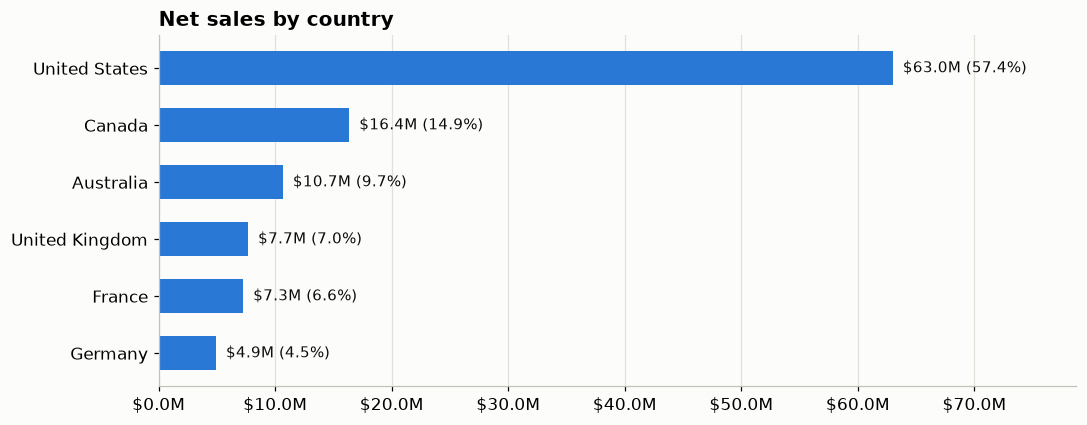

In [17]:
countries = query(f"""
    select
        a.countryregion_name as country
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.orderqty) as units
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    join {mart}.dim_addresses as a on f.fk_shiptoaddressid = a.pk_addressid
    group by 1
    order by net_sales desc
""")
countries["share_of_net_sales_pct"] = countries["net_sales"] / countries["net_sales"].sum() * 100
countries["avg_order_value"] = countries["net_sales"] / countries["orders"]
display(countries)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(countries["country"], countries["net_sales"], color=BLUE, height=0.6)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(millions))
ax.set_title("Net sales by country")
horizontal_grid(ax)
label_bars(ax, lambda value: f"{millions(value)} ({value / countries['net_sales'].sum():.1%})")
ax.margins(x=0.25)
plt.tight_layout()
plt.show()

states = query(f"""
    select
        a.stateprovince_name as state
        , a.countryregion_name as country
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    join {mart}.dim_addresses as a on f.fk_shiptoaddressid = a.pk_addressid
    group by 1, 2
    order by net_sales desc
    limit 8
""")
display(states)

**Insight**
- **Sales are spread across cities.** The top 5 cities together are only about 11% of net sales. Toronto leads with about US$ 4.5M, followed by London, Paris, Seattle and Burnaby, so a "top 5 cities" view will always show a modest share of the total.
- **Value and order count rank differently.** Toronto has the highest value from only 176 orders (about US$ 25,000 per order, a reseller-driven pattern), while London (756 orders) and Paris (575 orders) have many more orders at much lower values (online-driven).
- **The United States is 57% of net sales**, then Canada (15%), Australia (10%), the United Kingdom (7%), France (7%) and Germany (4%). Australia has the second-highest number of orders (6,843) among countries but only 10% of value, because its orders are small online orders.
- The United Kingdom has a single state/province value (England), so the state filter adds nothing for that country.

## 8. Payment

**Question:** how are orders spread across card types, and what do orders without a card look like?

,card_type,orders,net_sales,share_of_net_sales_pct
0,ColonialVoice,7678,"32,454,359.10",29.55
1,Vista,7432,"27,719,114.35",25.23
2,SuperiorCard,7634,"24,960,746.33",22.72
3,Distinguish,7590,"23,344,371.93",21.25
4,No card,1131,"1,367,789.69",1.25


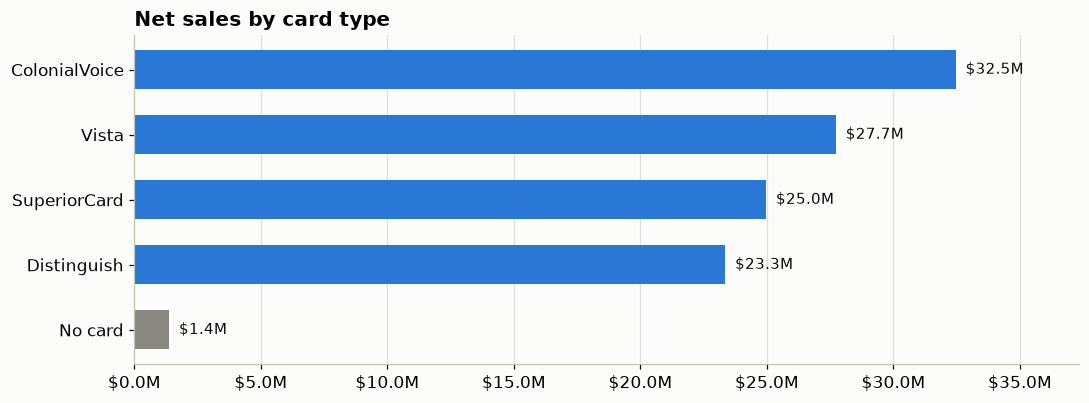

In [18]:
cards = query(f"""
    select
        coalesce(c.cardtype, 'No card') as card_type
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    left join {mart}.dim_credit_cards as c on f.fk_creditcardid = c.pk_creditcardid
    group by 1
    order by net_sales desc
""")
cards["share_of_net_sales_pct"] = cards["net_sales"] / cards["net_sales"].sum() * 100
display(cards)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(cards["card_type"], cards["net_sales"], color=[GRAY if t == "No card" else BLUE for t in cards["card_type"]], height=0.6)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(millions))
ax.set_title("Net sales by card type")
horizontal_grid(ax)
label_bars(ax, millions)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

**Insight**
- The four card types are close in size (each between 7,400 and 7,700 orders; US$ 23M-32M). Card type shows no strong skew, so it is a useful filter for question a but not a strong analytical axis.
- 1,131 orders (3.6%) have no card and carry about US$ 1.4M. They must stay in the totals as "No card".
- Card numbers are intentionally not loaded into the warehouse (sensitive data).

## 9. Sales reasons (question f)

**Question:** why do customers buy, and which product sells the most under the "Promotion" reason? An order can have several reasons, which are modeled in a bridge table.

In [19]:
reason_coverage = query(f"""
    select
        (select count(distinct fk_salesorderid) from {mart}.bridge_sales_order_reasons) as orders_with_reason
        , (select count(*) from {mart}.bridge_sales_order_reasons) as order_reason_pairs
        , (select count(*) from (
            select fk_salesorderid from {mart}.bridge_sales_order_reasons group by 1 having count(*) > 1
        )) as orders_with_several_reasons
        , (select sum(salesorderdetailnetsubtotal) from {mart}.fact_sales
            where fk_salesorderid in (select fk_salesorderid from {mart}.bridge_sales_order_reasons)) as net_sales_of_those_orders
        , (select sum(f.salesorderdetailnetsubtotal) from {mart}.fact_sales as f
            join {mart}.bridge_sales_order_reasons as b on f.fk_salesorderid = b.fk_salesorderid) as net_sales_summed_over_reasons
""")
display(reason_coverage)

,orders_with_reason,order_reason_pairs,orders_with_several_reasons,net_sales_of_those_orders,net_sales_summed_over_reasons
0,23012,27647,4482,"22,430,131.57","30,856,531.52"


,reason,reasontype,orders,units,net_sales
0,Price,Other,17473,47733,"10,975,842.56"
1,On Promotion,Promotion,3515,7390,"6,361,828.95"
2,Manufacturer,Other,1746,1818,"5,998,122.10"
3,Quality,Other,1551,1551,"5,549,896.77"
4,Other,Other,1395,3653,"248,483.34"
5,Review,Other,1245,1640,"1,694,881.98"
6,Television Advertisement,Marketing,722,730,"27,475.82"


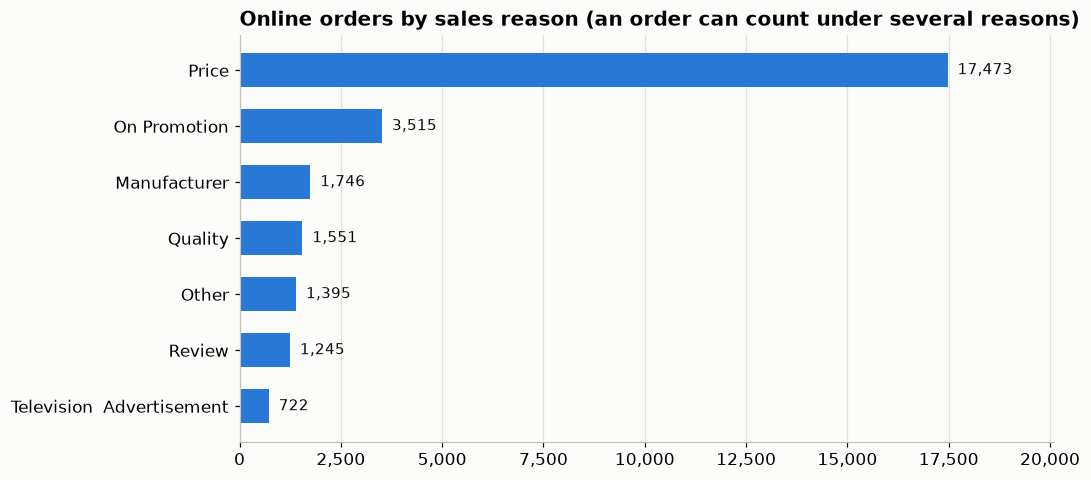

In [20]:
reasons = query(f"""
    select
        r.salesreason_name as reason
        , r.reasontype
        , count(distinct f.fk_salesorderid) as orders
        , sum(f.orderqty) as units
        , sum(f.salesorderdetailnetsubtotal) as net_sales
    from {mart}.fact_sales as f
    join {mart}.bridge_sales_order_reasons as b on f.fk_salesorderid = b.fk_salesorderid
    join {mart}.dim_sales_reasons as r on b.fk_salesreasonid = r.pk_salesreasonid
    group by 1, 2
    order by orders desc
""")
display(reasons)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(reasons["reason"], reasons["orders"], color=BLUE, height=0.6)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.set_title("Online orders by sales reason (an order can count under several reasons)")
horizontal_grid(ax)
label_bars(ax, lambda value: f"{value:,.0f}")
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

,product_name,units,orders
0,Water Bottle - 30 oz.,546,546
1,Road Bottle Cage,416,416
2,AWC Logo Cap,301,301
3,"Mountain-200 Black, 42",299,299
4,"Mountain-200 Black, 46",286,286


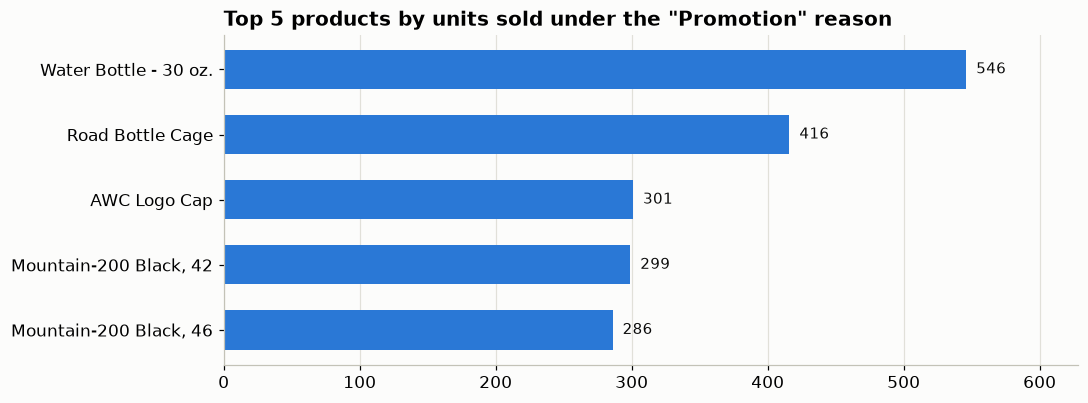

In [21]:
# Question f: product with the most units under the "Promotion" reason (reason name: On Promotion)
promotion_products = query(f"""
    select
        p.product_name
        , sum(f.orderqty) as units
        , count(distinct f.fk_salesorderid) as orders
    from {mart}.fact_sales as f
    join {mart}.bridge_sales_order_reasons as b on f.fk_salesorderid = b.fk_salesorderid
    join {mart}.dim_sales_reasons as r on b.fk_salesreasonid = r.pk_salesreasonid
    join {mart}.dim_products as p on f.fk_productid = p.pk_productid
    where r.reasontype = 'Promotion'
    group by 1
    order by units desc
    limit 5
""")
display(promotion_products)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(promotion_products["product_name"], promotion_products["units"], color=BLUE, height=0.6)
ax.invert_yaxis()
ax.set_title('Top 5 products by units sold under the "Promotion" reason')
horizontal_grid(ax)
label_bars(ax, lambda value: f"{value:,.0f}")
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

**Insight**
- **Sales reasons exist only for online orders.** None of the 3,806 reseller orders has a reason, and 4,647 online orders have none either, which makes up the 8,453 orders without reason. Any analysis by reason describes online customers only (83% of online orders).
- **Price is the dominant reason** (17,473 orders), followed by "On Promotion" (3,515 orders), Manufacturer and Quality.
- **Reasons overlap.** 4,482 orders carry more than one reason, so there are 27,647 order-reason pairs for 23,012 orders. Adding net sales across reasons would give US$ 30.9M for orders that really total US$ 22.4M (see the table in this section). Dashboard visuals by reason must never show a grand total that adds the reasons.
- **Question f: the product with the most units under "Promotion" is the Water Bottle - 30 oz. (546 units)**, followed by the Road Bottle Cage (416) and the AWC Logo Cap (301). The Mountain-200 bikes also appear in the top 5, so promotions move both low-price accessories and high-price bikes.

## 10. Discounts

**Question:** discounts are 0.48% of gross sales overall. Where are they concentrated?

,category,channel,order_lines,discounted_lines,discount_amount,gross_sales,discounted_lines_pct,discount_pct_of_gross
0,Bikes,Reseller,24826,1409,"494,640.65","66,827,668.70",5.68,0.74
1,Clothing,Reseller,12293,1212,"20,964.50","1,801,734.41",9.86,1.16
2,Accessories,Reseller,5102,575,"6,688.03","578,000.95",11.27,1.16
3,Components,Reseller,18698,86,"5,214.74","11,807,808.02",0.46,0.04
4,Bikes,Online,15205,0,0.00,"28,318,144.65",0.00,0.00
5,Clothing,Online,9101,0,0.00,"339,772.61",0.00,0.00
6,Accessories,Online,36092,0,0.00,"700,759.96",0.00,0.00


,discount_rate,order_lines,discount_amount
0,0.20,231,"145,332.91"
1,0.35,137,"135,114.91"
2,0.15,590,"80,132.13"
3,0.02,1310,"59,004.52"
4,0.05,606,"54,612.81"
5,0.30,61,"21,422.61"
6,0.40,169,"17,266.09"
7,0.10,178,"14,621.93"


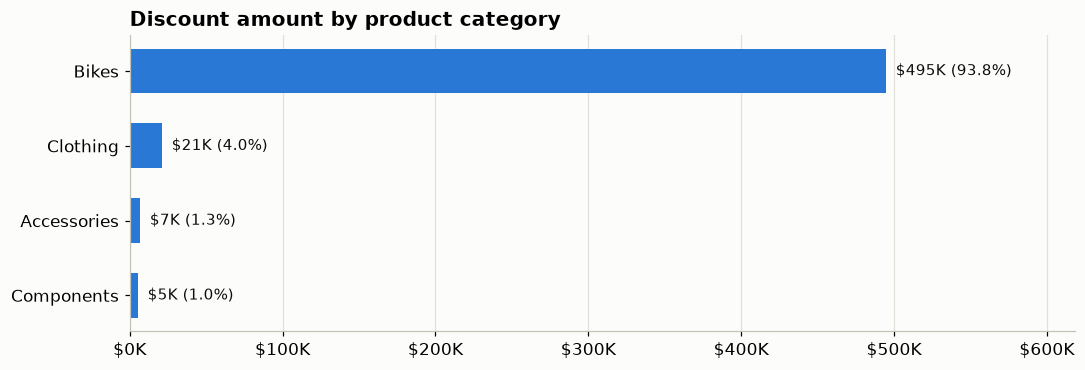

In [22]:
discounts = query(f"""
    select
        p.productcategory_name as category
        , case when f.onlineorderflag then 'Online' else 'Reseller' end as channel
        , count(*) as order_lines
        , sum(case when f.unitpricediscount > 0 then 1 else 0 end) as discounted_lines
        , sum(f.salesorderdetaildiscount) as discount_amount
        , sum(f.salesorderdetailsubtotal) as gross_sales
    from {mart}.fact_sales as f
    join {mart}.dim_products as p on f.fk_productid = p.pk_productid
    group by 1, 2
    order by discount_amount desc
""")
discounts["discounted_lines_pct"] = discounts["discounted_lines"] / discounts["order_lines"] * 100
discounts["discount_pct_of_gross"] = discounts["discount_amount"] / discounts["gross_sales"] * 100
display(discounts)

discount_rates = query(f"""
    select
        unitpricediscount as discount_rate
        , count(*) as order_lines
        , sum(salesorderdetaildiscount) as discount_amount
    from {mart}.fact_sales
    where unitpricediscount > 0
    group by 1
    order by discount_amount desc
""")
display(discount_rates)

by_category = discounts.groupby("category")["discount_amount"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(by_category.index, by_category.values, color=BLUE, height=0.6)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(thousands))
ax.set_title("Discount amount by product category")
horizontal_grid(ax)
label_bars(ax, lambda value: f"{thousands(value)} ({value / by_category.sum():.1%})")
ax.margins(x=0.25)
plt.tight_layout()
plt.show()

**Insight**
- Only about 2.7% of order lines carry a discount, and the total discount is about US$ 0.53M. Bikes account for roughly 94% of the amount.
- **Every discount is on a reseller order.** No online order line has a discount (the table shows 0 discounted online lines in all categories). Within resellers, 0.7% of bike value is discounted, against 1.2% for clothing and accessories.
- Discount rates range from 2% to 40%; the largest amounts come from a few deep discounts (20%, 35%, 15%) rather than from the many 2% lines. For the dashboard, discount is a secondary KPI, but it is needed to reproduce the question b formula (gross sales − discounts).

## 11. Data caveats and recommendations

### What the dashboard must handle
| Finding | Dashboard decision |
|---|---|
| 2011 (from May 31) and 2014 (to June 30) are partial years; June 2014 has no bike sales | Show the period covered; compare equal month ranges; exclude June 2014 from growth KPIs or flag it |
| Channel = customer type, and the two channels differ ~20x in order value | Channel filter on every page; show averages by channel |
| Sales reasons exist only for online orders, and orders can have several reasons | Label the reason view "online orders"; never add orders or value across reasons; include "No reason" |
| 1,131 orders without a card | Keep as "No card" |
| Only 266 of 504 products have sales | Build product filters from products with sales |
| Order status is the same for all orders | Keep the filter (required by question a) but do not build analysis on it |
| Header amounts (`subtotal`, `taxamt`, `freight`, `totaldue`) repeat on each order line | Never sum them from `fact_sales`; use the three line-level measures |

### Actionable recommendations for the business
1. **Protect the reseller base.** About 635 stores bring about 73% of net sales and the top 10% of customers bring about 82%. Account management and reseller-level reporting should be a commercial priority, and the reseller calendar should be reviewed, as several months have almost no reseller orders.
2. **Raise the value of online orders.** Online order volume grew about 8x per month after mid-2013, but the average order dropped about two thirds as accessories and clothing entered the mix. Bundling accessories with bike purchases and cross-selling to the many one-time buyers (about 61% of customers) can lift revenue per customer without new acquisition.
3. **Use promotions on purpose.** "On Promotion" is the second most common online reason and moves low-price items (bottle, bottle cage, cap) and bikes. Tracking promotion orders by product, not only by reason, would show whether promotions bring incremental bike sales or only accessories.
4. **Treat discounts as a targeted tool.** They are under 0.5% of gross sales and concentrated in bikes at a few deep rates; a review of the 20% and 35% discounts is the only place where meaningful value is at stake.
5. **Read growth carefully.** 2013 grew about 30% over 2012, but the gain came in the second half; use equal-month comparisons in executive reports.